In [1]:
from google.colab import files
uploaded = files.upload()

Saving zdanie.wav to zdanie.wav
Saving slowo.wav to slowo.wav
Saving samogloska.wav to samogloska.wav


Porównanie nagrań (domyślne parametry)

wykresy dla: samogloska.wav
analiza pliku: samogloska.wav


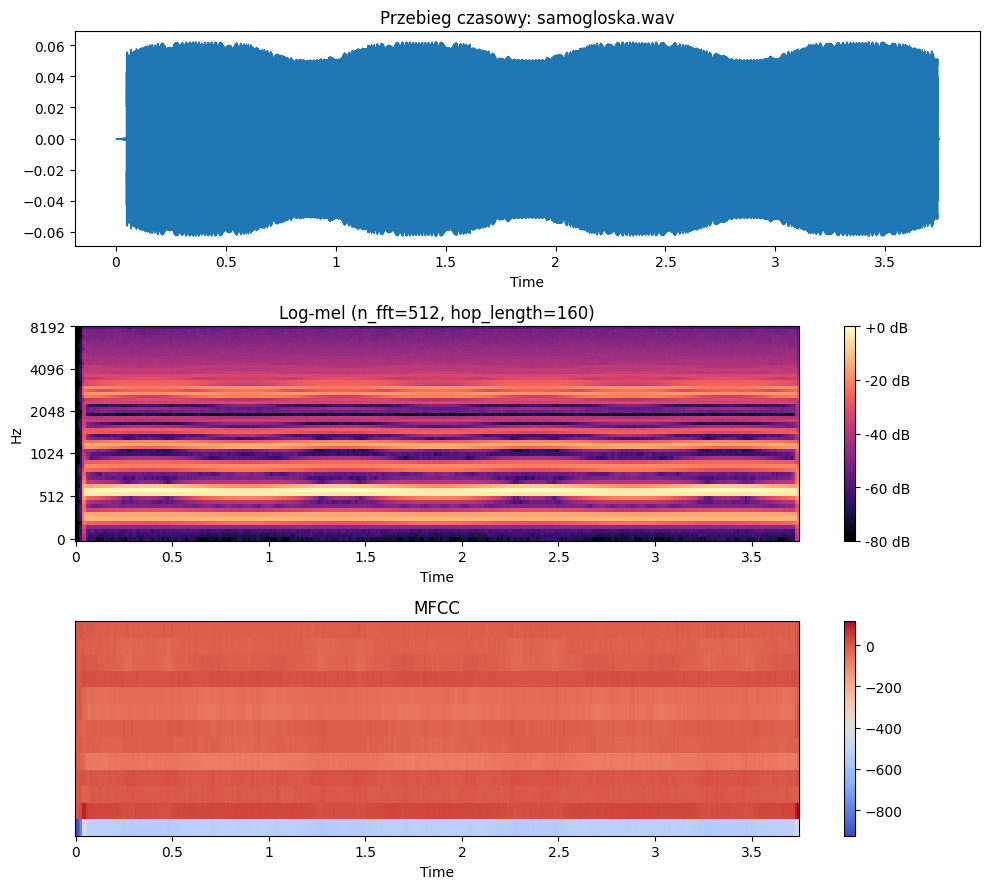


wykresy dla: slowo.wav
analiza pliku: slowo.wav


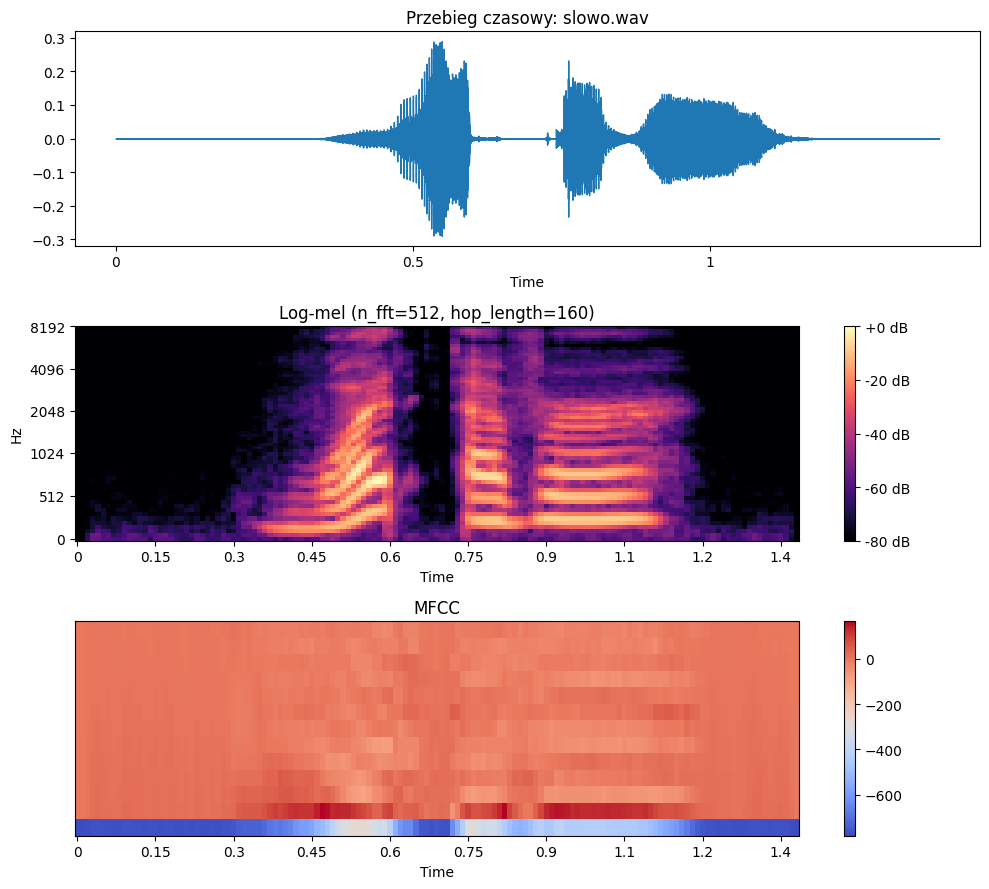


wykresy dla: zdanie.wav
analiza pliku: zdanie.wav


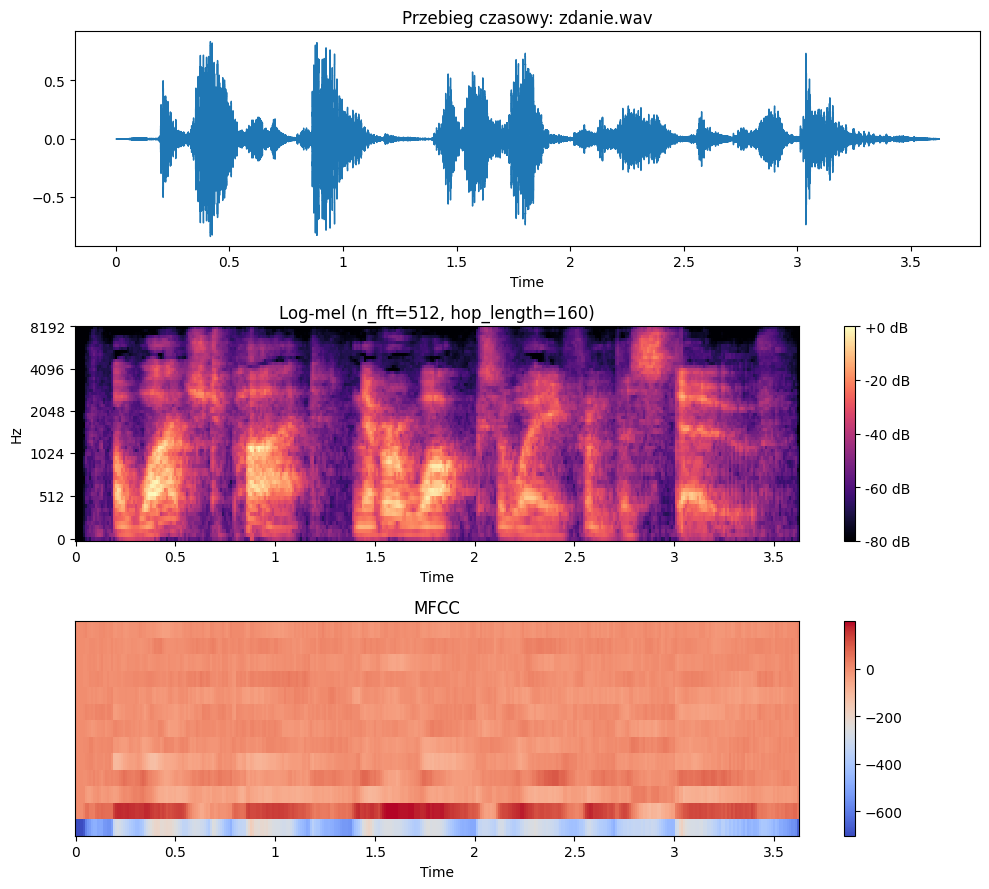

Badanie wpływu parametrów (na przykładzie slowo.wav)
Opcja A: Lepsza rozdzielczość czasowa (n_fft=256, hop_length=80)
analiza pliku: slowo.wav


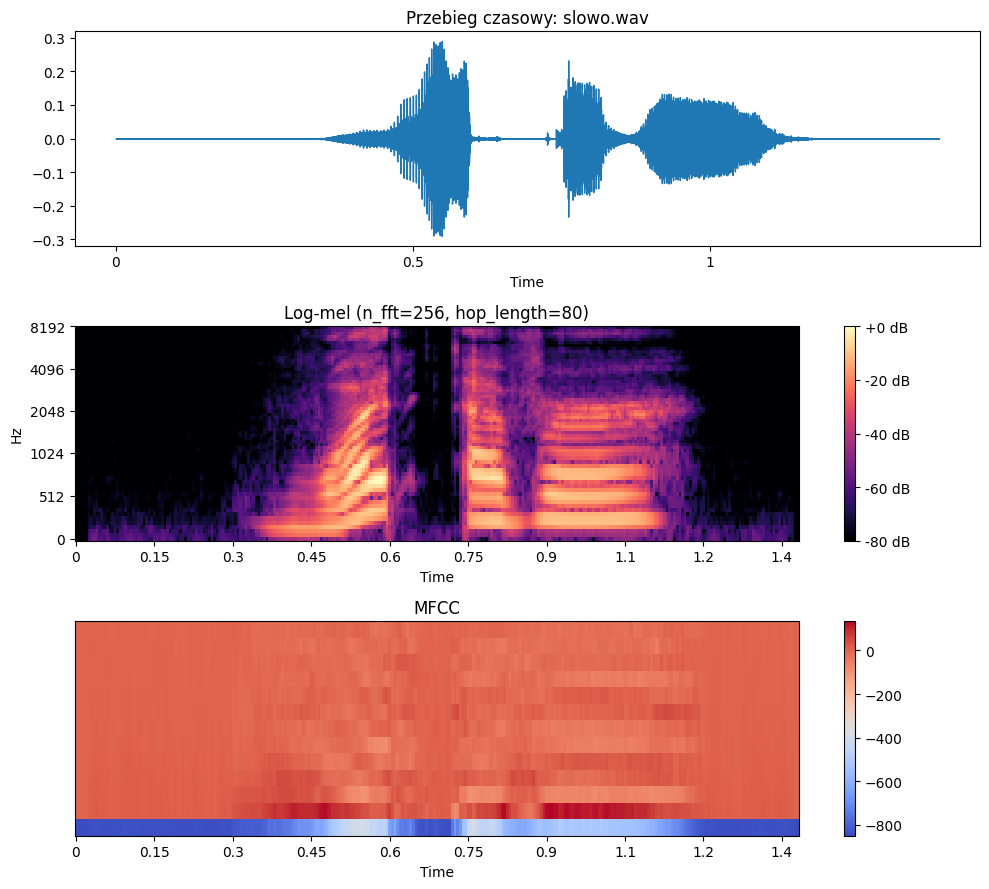

Opcja B: Lepsza rozdzielczość częstotliwościowa (n_fft=1024, hop_length=320)
analiza pliku: slowo.wav


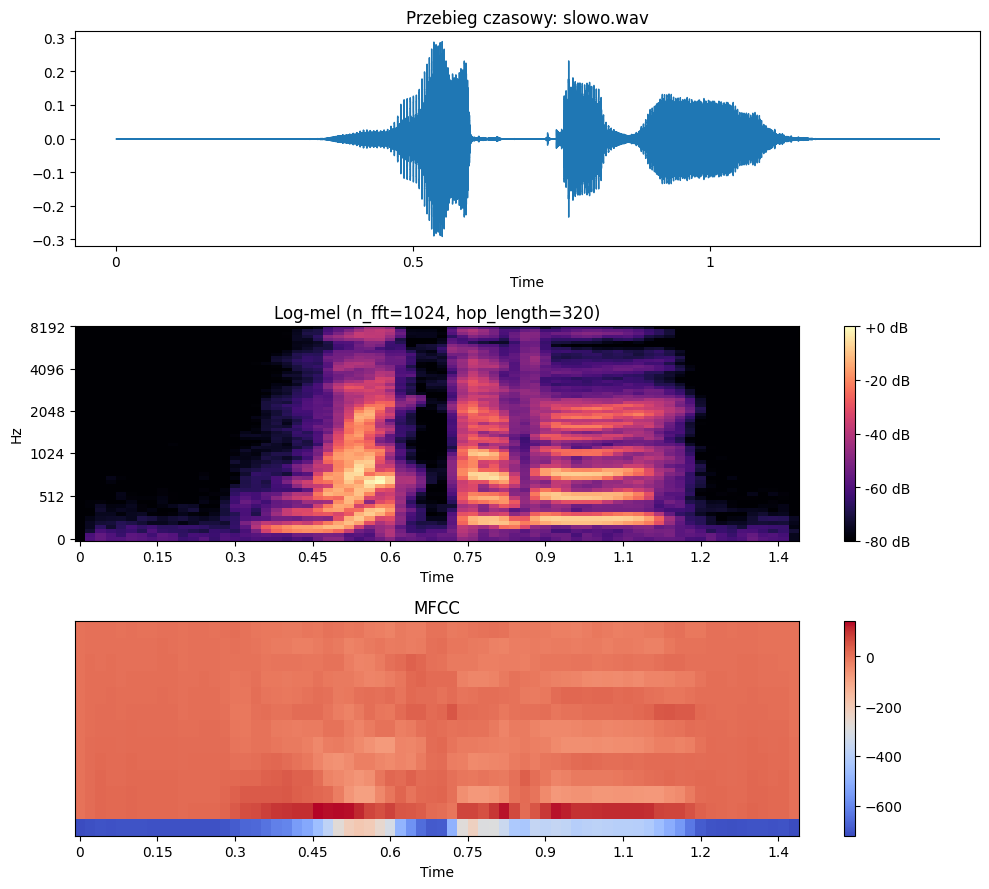

In [10]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

#konfiguracja bazowa
SR = 16000
N_MELS = 64

def analyze_audio(file_path, n_fft=512, hop_length=160):
    """Wczytuje audio, oblicza reprezentacje i generuje wykresy."""
    y, sr = librosa.load(file_path, sr=SR, mono=True)


    print(f"analiza pliku: {file_path}")
    display(Audio(y, rate=sr))


    #obliczenia Log-mel i MFCC
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=N_MELS)
    S_db = librosa.power_to_db(S, ref=np.max)
    M = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, n_fft=n_fft, hop_length=hop_length)

    #wykresy
    fig, ax = plt.subplots(3, 1, figsize=(10, 9))

    librosa.display.waveshow(y, sr=sr, ax=ax[0])
    ax[0].set_title(f"Przebieg czasowy: {file_path}")

    img1 = librosa.display.specshow(S_db, sr=sr, hop_length=hop_length, x_axis="time", y_axis="mel", ax=ax[1])
    ax[1].set_title(f"Log-mel (n_fft={n_fft}, hop_length={hop_length})")
    fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

    img2 = librosa.display.specshow(M, sr=sr, hop_length=hop_length, x_axis="time", ax=ax[2])
    ax[2].set_title("MFCC")
    fig.colorbar(img2, ax=ax[2])

    plt.tight_layout()
    plt.show()


audio_files = ['samogloska.wav', 'slowo.wav', 'zdanie.wav']

print("Porównanie nagrań (domyślne parametry)")
for file in audio_files:
    print(f"\nwykresy dla: {file}")
    analyze_audio(file)

print("Badanie wpływu parametrów (na przykładzie slowo.wav)")

print("Opcja A: Lepsza rozdzielczość czasowa (n_fft=256, hop_length=80)")
analyze_audio('slowo.wav', n_fft=256, hop_length=80)

print("Opcja B: Lepsza rozdzielczość częstotliwościowa (n_fft=1024, hop_length=320)")
analyze_audio('slowo.wav', n_fft=1024, hop_length=320)